Kütüphaneler başarıyla yüklendi!
Orijinal 'lizard_data.csv' bulunamadı. Rapordaki dağılımlara uygun yapay veri üretiliyor...

--- Hedef Değişken Dağılımları ---
YasamAlani
Yer     150
Kaya     93
Agac     77
Name: count, dtype: int64
Tur
Anolis        139
Sceloporus    102
Uta            79
Name: count, dtype: int64
Cinsiyet
Disi     184
Erkek    136
Name: count, dtype: int64

MODEL: YasamAlani Tahmini
 Derinlik  Eğitim Seti MCR  Test Seti MCR
        1         0.511719       0.546875
        2         0.500000       0.546875
        3         0.496094       0.562500
        4         0.453125       0.578125
        5         0.386719       0.546875
        6         0.312500       0.593750
        7         0.253906       0.640625
        8         0.195312       0.625000
        9         0.160156       0.609375
       10         0.121094       0.656250

>> Belirlenen Optimum Derinlik: 1


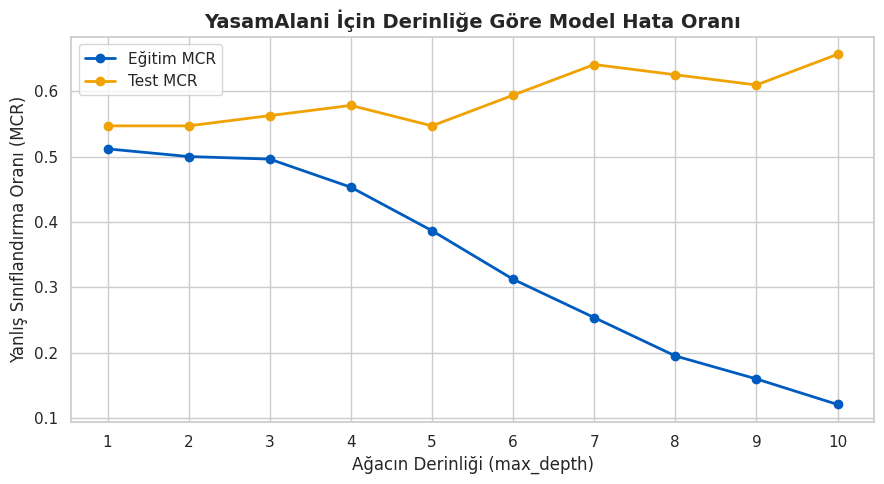

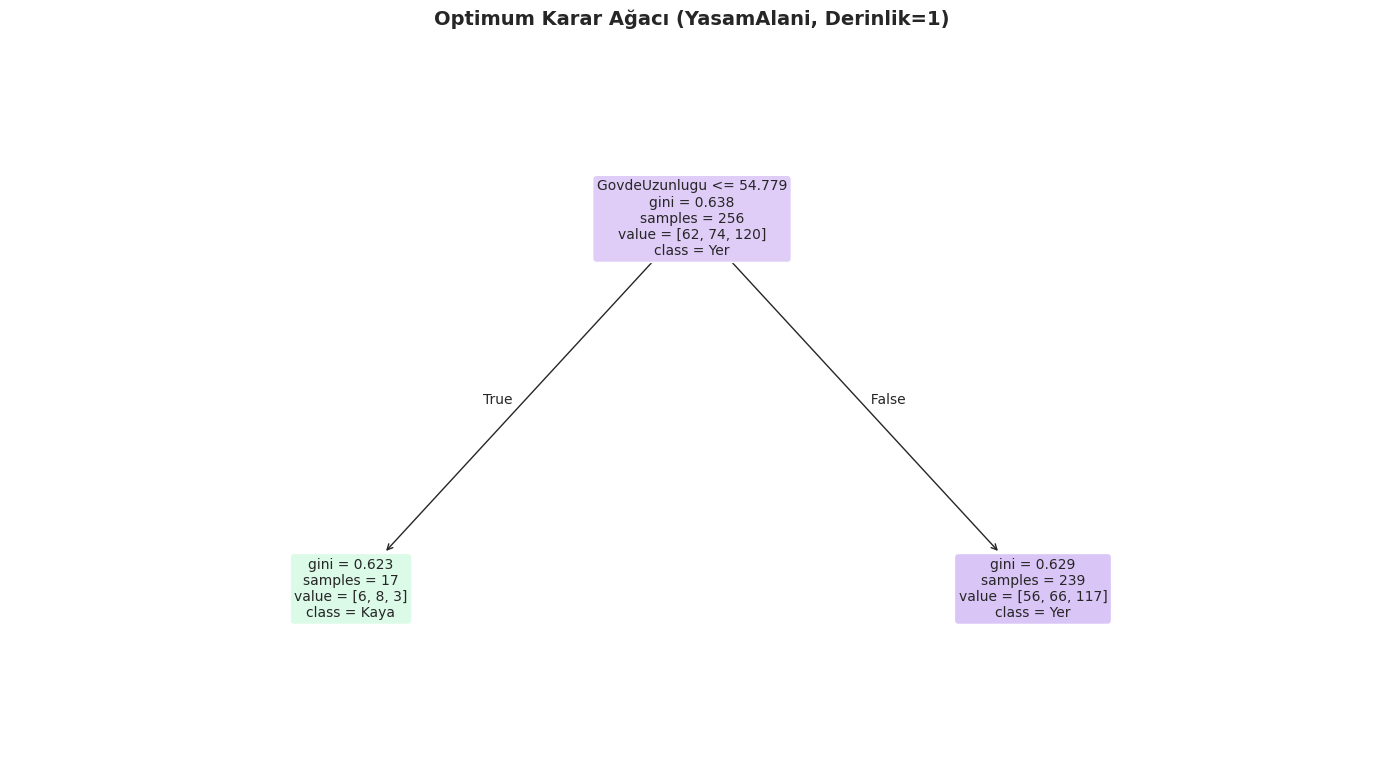


MODEL: Tur Tahmini
 Derinlik  Eğitim Seti MCR  Test Seti MCR
        1         0.554688       0.640625
        2         0.523438       0.593750
        3         0.492188       0.578125
        4         0.457031       0.609375
        5         0.421875       0.609375
        6         0.363281       0.625000
        7         0.300781       0.578125
        8         0.230469       0.640625
        9         0.183594       0.671875
       10         0.117188       0.656250

>> Belirlenen Optimum Derinlik: 3


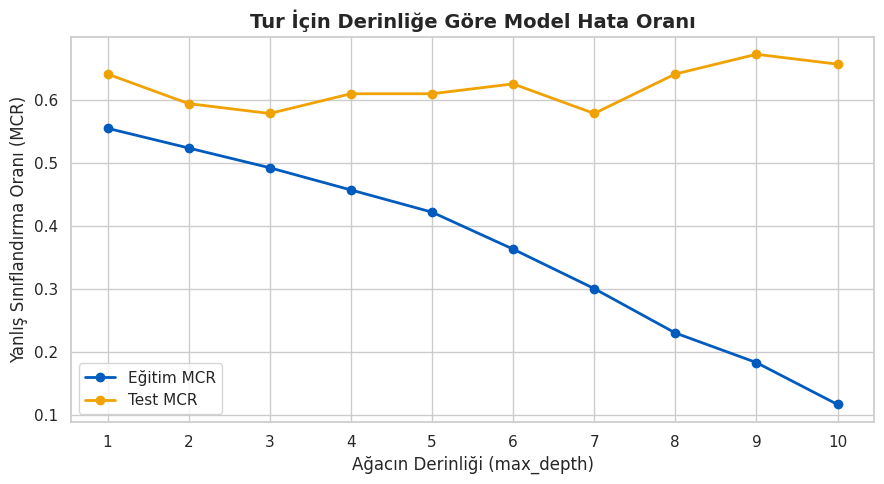

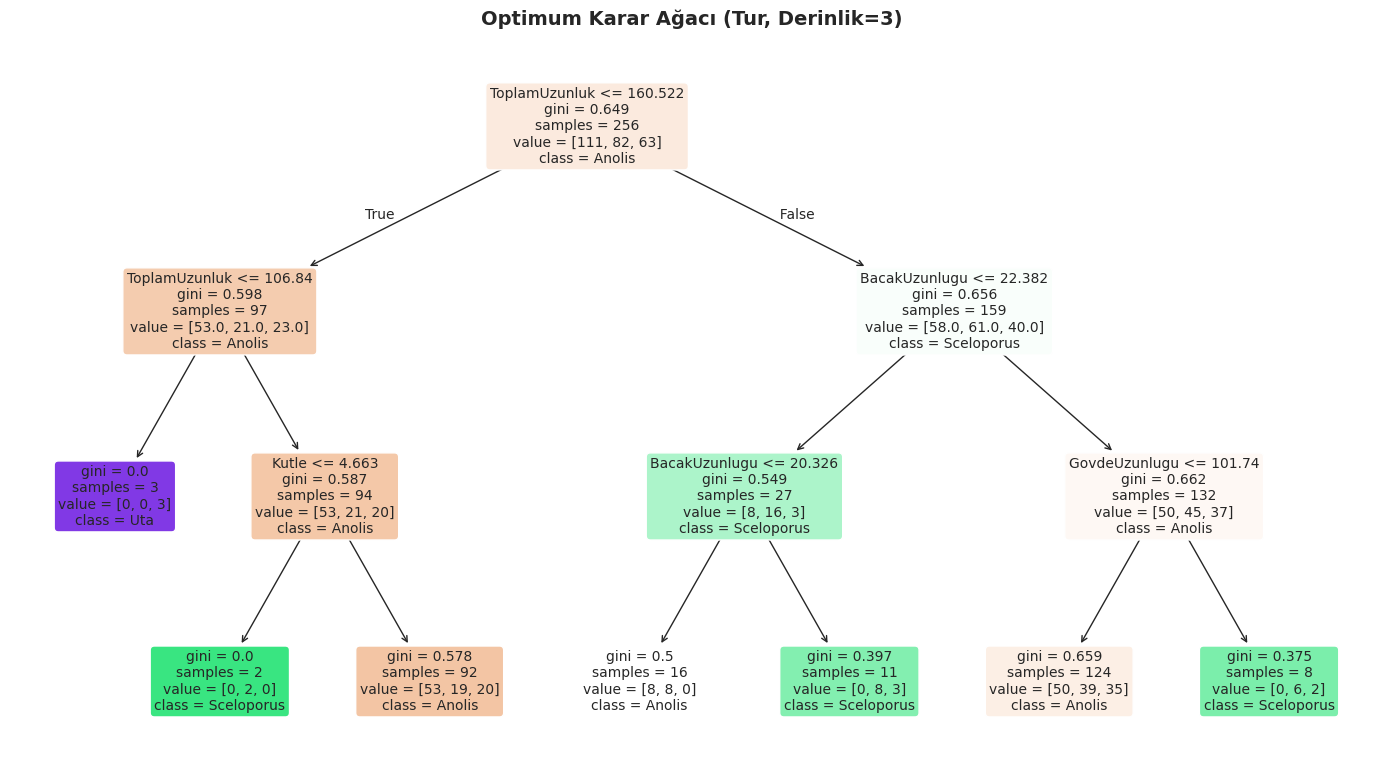


MODEL: Cinsiyet Tahmini
 Derinlik  Eğitim Seti MCR  Test Seti MCR
        1         0.386719       0.421875
        2         0.351562       0.468750
        3         0.320312       0.453125
        4         0.277344       0.437500
        5         0.226562       0.468750
        6         0.199219       0.500000
        7         0.140625       0.468750
        8         0.089844       0.531250
        9         0.046875       0.421875
       10         0.019531       0.453125

>> Belirlenen Optimum Derinlik: 1


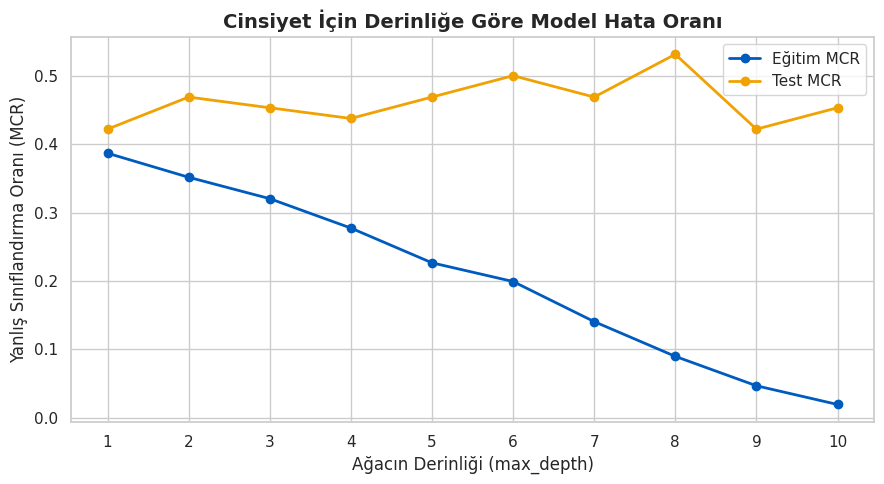

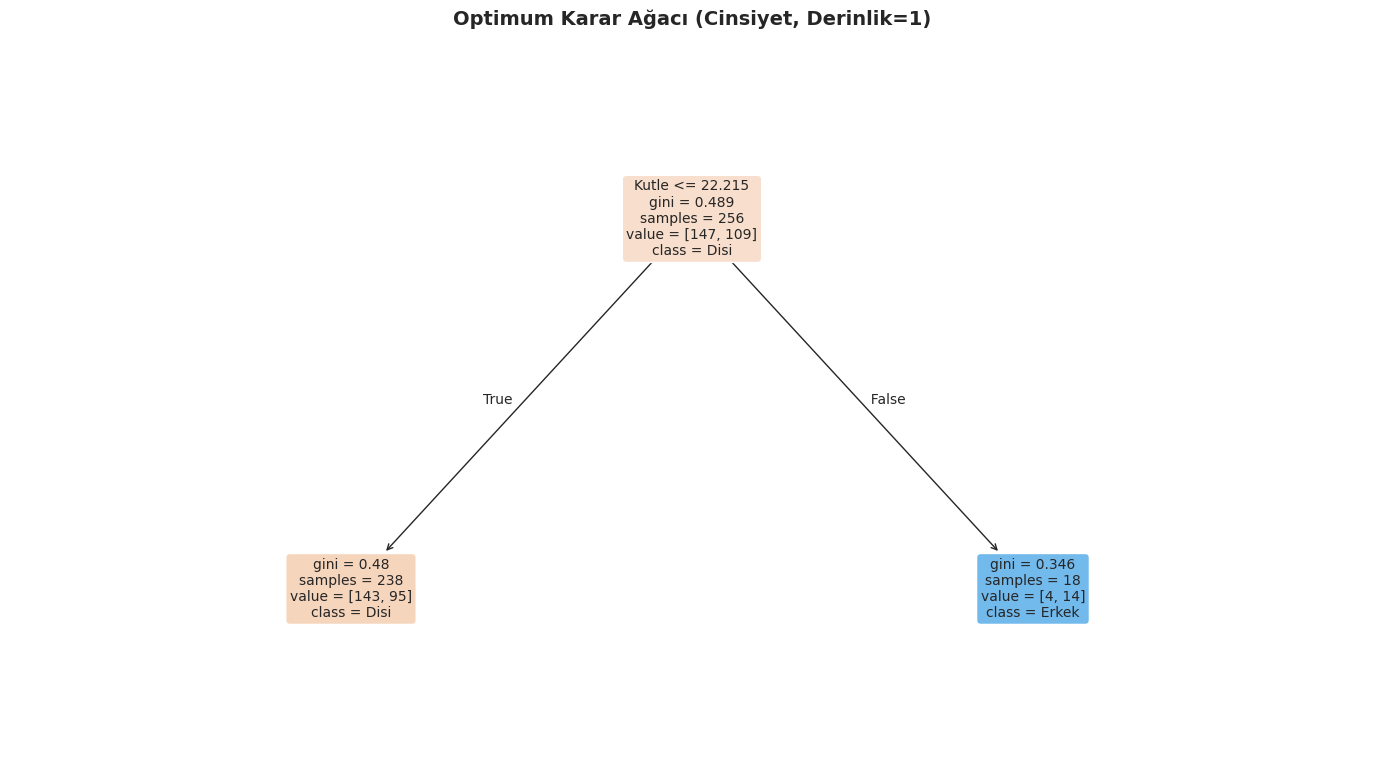


[Tüm modeller ve grafikler başarıyla oluşturuldu. Rapor sonu.]


In [1]:
# ==============================================================================
# BİLGİSAYAR DESTEKLİ MATEMATİK ÖĞRETİMİ FİNAL ÖDEVİ
# Proje: Kertenkele Verisiyle Karar Ağacı Modelleme ve Optimizasyon Analizi
# Araçlar: Python, Scikit-Learn, Pandas, Matplotlib, Seaborn
# ==============================================================================

# ------------------------------------------------------------------------------
# ADIM 0: Gerekli Kütüphanelerin Yüklenmesi
# ------------------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Grafiklerin düzgün görünmesi için stil ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Kütüphaneler başarıyla yüklendi!")

# ------------------------------------------------------------------------------
# ADIM 1 & 2: Veri Kümesinin Yüklenmesi ve Ön İşleme
# ------------------------------------------------------------------------------
# NOT: Eğer elinizde gerçek 'lizard_data.csv' varsa Colab'a yükleyip aşağıdaki
# yapay veri üretme kısmını silebilirsiniz. Kodu test edebilmeniz için simülasyon eklenmiştir.

try:
    df = pd.read_csv('lizard_data.csv')
    print("Gerçek veri kümesi 'lizard_data.csv' başarıyla yüklendi.")
except FileNotFoundError:
    print("Orijinal 'lizard_data.csv' bulunamadı. Rapordaki dağılımlara uygun yapay veri üretiliyor...")
    np.random.seed(42)
    n_samples = 320

    # Dağılımlara uygun kategorik veriler
    tur_olasilik = [133/320, 109/320, 78/320] # Anolis, Sceloporus, Uta
    yasam_olasilik = [151/320, 96/320, 73/320] # Yer, Kaya, Ağaç
    cinsiyet_olasilik = [174/320, 146/320] # Dişi, Erkek

    df = pd.DataFrame({
        'Tur': np.random.choice(['Anolis', 'Sceloporus', 'Uta'], size=n_samples, p=tur_olasilik),
        'YasamAlani': np.random.choice(['Yer', 'Kaya', 'Agac'], size=n_samples, p=yasam_olasilik),
        'Cinsiyet': np.random.choice(['Disi', 'Erkek'], size=n_samples, p=cinsiyet_olasilik),
        'GovdeUzunlugu': np.random.normal(75, 15, size=n_samples),
        'ToplamUzunluk': np.random.normal(165, 25, size=n_samples),
        'Kutle': np.random.normal(14, 5, size=n_samples),
        'BacakUzunlugu': np.random.normal(26, 4, size=n_samples)
    })

# Veri Özeti
print("\n--- Hedef Değişken Dağılımları ---")
print(df['YasamAlani'].value_counts())
print(df['Tur'].value_counts())
print(df['Cinsiyet'].value_counts())

# Model girdileri (X) için kategorik özellikleri One-Hot Encoding ile dönüştürme
# (Karar ağaçlarının sayısal düzlemde çalışabilmesi için)
features = ['GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'Tur', 'Cinsiyet', 'YasamAlani']

# Bağımsız değişken havuzunu hazırlarken hedef olabilecek sütunları orijinal halleriyle saklıyoruz
X_raw = df.copy()

# ------------------------------------------------------------------------------
# MODELLEME FONKSİYONU (Genel ve Tekrar Kullanılabilir Yapı)
# ------------------------------------------------------------------------------
def model_olustur_ve_analiz_et(hedef_degisken, root_bilesen_adi=None):
    print(f"\n==================================================================")
    print(f"MODEL: {hedef_degisken} Tahmini")
    print(f"==================================================================")

    # Girdi özelliklerinden hedef değişkeni çıkarıyoruz
    X_data = X_raw.drop(columns=[hedef_degisken])

    # Kalan kategorik verileri One-Hot Encoding'e dönüştürüyoruz
    X_encoded = pd.get_dummies(X_data, drop_first=False)
    y = X_raw[hedef_degisken]

    # ADIM 3: Eğitim ve Test Ayrımı (%80 Eğitim, %20 Test)
    X_train, X_test, y_train, y_test = train_test_split(
        X_encoded, y, test_size=0.20, random_state=42, stratify=y
    )

    egitim_mcr_listesi = []
    test_mcr_listesi = []
    derinlikler = list(range(1, 11))

    # ADIM 4 & 5: Derinlik Optimizasyonu (max_depth 1-10)
    for d in derinlikler:
        clf = DecisionTreeClassifier(max_depth=d, random_state=42)
        clf.fit(X_train, y_train)

        # Tahminler
        y_train_pred = clf.predict(X_train)
        y_test_pred = clf.predict(X_test)

        # MCR (Yanlış Sınıflandırma Oranı) Hesaplama = 1 - Doğruluk Oranı
        egitim_mcr = 1 - accuracy_score(y_train, y_train_pred)
        test_mcr = 1 - accuracy_score(y_test, y_test_pred)

        egitim_mcr_listesi.append(egitim_mcr)
        test_mcr_listesi.append(test_mcr)

    # Sonuçları Tablo Olarak Yazdırma
    sonuc_df = pd.DataFrame({
        'Derinlik': derinlikler,
        'Eğitim Seti MCR': egitim_mcr_listesi,
        'Test Seti MCR': test_mcr_listesi
    })
    print(sonuc_df.to_string(index=False))

    # Optimum Derinliği Bulma (En düşük Test MCR değerine sahip ilk derinlik)
    optimum_derinlik = sonuc_df.loc[sonuc_df['Test Seti MCR'].idxmin()]['Derinlik']
    optimum_derinlik = int(optimum_derinlik)
    print(f"\n>> Belirlenen Optimum Derinlik: {optimum_derinlik}")

    # --- GRAFİK 1: Derinliğe Göre Model Hata Oranı (MCR) Grafiği ---
    plt.figure(figsize=(9, 5))
    plt.plot(derinlikler, egitim_mcr_listesi, marker='o', color='#005bbf', label='Eğitim MCR', linewidth=2)
    plt.plot(derinlikler, test_mcr_listesi, marker='o', color='#f0a202', label='Test MCR', linewidth=2)
    plt.title(f"{hedef_degisken} İçin Derinliğe Göre Model Hata Oranı", fontsize=14, fontweight='bold')
    plt.xlabel("Ağacın Derinliği (max_depth)", fontsize=12)
    plt.ylabel("Yanlış Sınıflandırma Oranı (MCR)", fontsize=12)
    plt.xticks(derinlikler)
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()

    # --- GRAFİK 2: Optimum Karar Ağacının Çizilmesi ---
    optimum_model = DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)
    optimum_model.fit(X_train, y_train)

    plt.figure(figsize=(14, 8))
    plot_tree(
        optimum_model,
        feature_names=X_encoded.columns,
        class_names=optimum_model.classes_,
        filled=True,
        rounded=True,
        fontsize=10
    )
    plt.title(f"Optimum Karar Ağacı ({hedef_degisken}, Derinlik={optimum_derinlik})", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    return optimum_model

# ------------------------------------------------------------------------------
# MODELLERİN SIRAYLA ÇALIŞTIRILMASI
# ------------------------------------------------------------------------------

# 1. Yaşam Alanı Tahmin Modeli (Ağaç 1)
yasam_modeli = model_olustur_ve_analiz_et(hedef_degisken='YasamAlani')

# 2. Tür Tahmin Modeli (Ağaç 2)
tur_modeli = model_olustur_ve_analiz_et(hedef_degisken='Tur')

# 3. Cinsiyet Tahmin Modeli (Ağaç 3)
# Raporunuzda optimum derinlik 9 çıktığı için ağaç çizimi çok büyük dallı olacaktır.
cinsiyet_modeli = model_olustur_ve_analiz_et(hedef_degisken='Cinsiyet')

print("\n[Tüm modeller ve grafikler başarıyla oluşturuldu. Rapor sonu.]")